# Week 01 · Returns and the Maze Example — 반환값과 미로 예제

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week01_introduction/01_returns_and_maze.ipynb)

슬라이드 *"Return Definitions in Episodic Tasks"*, *"Return Definitions in Continuing Tasks"*,
*"Two Viewpoints on Discounted Rewards"*, *"Mathematical Options on Rewards"* 의 반환값(return) 계산과
*"Maze Example"*, *"Maze Example: RL-Solution by Policy / by Value Function / by Model Evaluation"* 을 코드로 재현합니다.
할인율 $\gamma$가 반환값을 어떻게 바꾸는지 보고, 같은 미로를 정책·가치 함수·모델이라는 세 가지 방식으로 풀어 봅니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이 노트북에서 추가로 쓰는 것
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

## 1. 반환값과 할인 (Return Definitions / Two Viewpoints on Discounted Rewards)

반환값(return) $G_t$는 시점 $t$ 이후에 받는 보상의 (할인된) 합입니다.

- 에피소드 과제(episodic task): $G_t = R_{t+1} + R_{t+2} + \cdots + R_N$ (유한한 합)
- 연속 과제(continuing task): $G_t = \sum_{i=0}^{\infty} \gamma^i R_{t+i+1}$, 할인율(discount rate) $0 \le \gamma \le 1$

슬라이드 *"Mathematical Options on Rewards"* 의 두 식도 함께 확인합니다.

$$G_t = R_{t+1} + \gamma G_{t+1}, \qquad \text{보상이 상수 } R \text{ 이고 } \gamma<1 \text{ 이면 } G_t = \sum_{i=0}^{\infty}\gamma^i R = \frac{R}{1-\gamma}.$$

(슬라이드의 두 번째 식은 좌변이 $R_t$로 적혀 있는데, 내용상 $G_t$의 오기로 보입니다.)

In [2]:
def discounted_return(rewards, gamma):
    """G_0 = R_1 + gamma*R_2 + gamma^2*R_3 + ...   (rewards = [R_1, R_2, ...])"""
    return sum(gamma**i * r for i, r in enumerate(rewards))


def all_returns(rewards, gamma):
    """G_t for every t, computed backwards with G_t = R_{t+1} + gamma * G_{t+1} (G_N = 0)."""
    G = np.zeros(len(rewards) + 1)
    for t in reversed(range(len(rewards))):
        G[t] = rewards[t] + gamma * G[t + 1]
    return G[:-1]


# (a) 에피소드 과제: 미로처럼 매 스텝 -1, 16스텝 뒤 종료 (아래 미로의 최단 경로 길이)
maze_rewards = [-1] * 16
print("episodic, gamma=1   : G_0 =", discounted_return(maze_rewards, 1.0))
print("G_t for t=0..15     :", all_returns(maze_rewards, 1.0))

# (b) 재귀식 G_t = R_{t+1} + gamma G_{t+1} 이 정의(앞에서부터 더하기)와 같은지 확인
r_seq = rng.normal(size=30)
forward = [discounted_return(r_seq[t:], 0.9) for t in range(len(r_seq))]
assert np.allclose(forward, all_returns(r_seq, 0.9))

# (c) 상수 보상 R=1 의 무한합 = R / (1 - gamma)
for gamma in [0.5, 0.9, 0.99]:
    G_long = discounted_return([1.0] * 5000, gamma)
    print(f"gamma={gamma:4}:  sum of 5000 terms = {G_long:8.4f}   R/(1-gamma) = {1 / (1 - gamma):8.4f}")
    assert abs(G_long - 1 / (1 - gamma)) < 1e-6

episodic, gamma=1   : G_0 = -16.0
G_t for t=0..15     : [-16. -15. -14. -13. -12. -11. -10.  -9.  -8.  -7.  -6.  -5.  -4.  -3.
  -2.  -1.]
gamma= 0.5:  sum of 5000 terms =   2.0000   R/(1-gamma) =   2.0000
gamma= 0.9:  sum of 5000 terms =  10.0000   R/(1-gamma) =  10.0000
gamma=0.99:  sum of 5000 terms = 100.0000   R/(1-gamma) = 100.0000


에피소드 과제에서 $G_t$를 뒤에서부터 계산하면 $-16, -15, \dots, -1$이 나옵니다. 이 숫자들은 아래 4절의 미로 가치 함수에서
최단 경로를 따라 적힌 값과 정확히 같습니다.

이제 슬라이드 *"Two Viewpoints on Discounted Rewards"* 의 두 관점을 그림으로 봅니다.

- 수치적 관점(numeric viewpoint): 보상 $R=1$을 계속 받을 때 부분합 $\sum_{i<T}\gamma^i$ — $\gamma<1$이면 $1/(1-\gamma)$로 수렴, $\gamma=1$이면 무한히 커집니다.
- 전략적 관점(strategic viewpoint): "지금 $+1$" 과 "4스텝 뒤 $+5$" 중 무엇이 더 좋은가? $G_{\text{now}} = 1$, $G_{\text{later}} = 5\gamma^4$ 이므로 $\gamma$에 따라 선택이 바뀝니다.

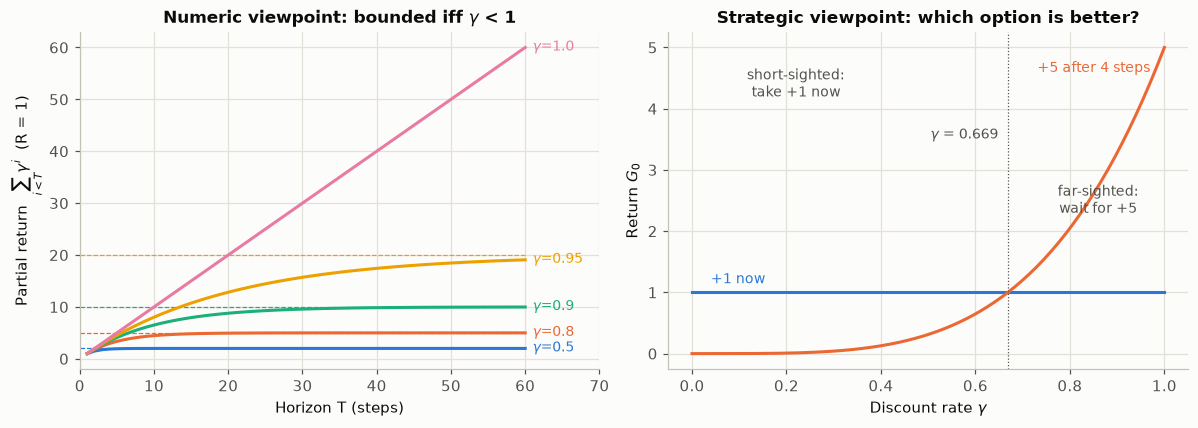

gamma= 0.1:  G(+1 now)=1.000  G(+5 later)=0.001  -> take +1 now
gamma= 0.5:  G(+1 now)=1.000  G(+5 later)=0.312  -> take +1 now
gamma= 0.9:  G(+1 now)=1.000  G(+5 later)=3.280  -> wait for +5
gamma=0.99:  G(+1 now)=1.000  G(+5 later)=4.803  -> wait for +5


In [3]:
T = np.arange(1, 61)
gammas = [0.5, 0.8, 0.9, 0.95, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
for i, gamma in enumerate(gammas):
    partial = np.cumsum(gamma ** np.arange(T[-1]))           # sum_{i<T} gamma^i
    ax.plot(T, partial, color=PALETTE[i])
    ax.text(T[-1] + 1, partial[-1], f"$\\gamma$={gamma}", color=PALETTE[i], va="center", fontsize=9)
    if gamma < 1:
        ax.hlines(1 / (1 - gamma), 0, T[-1], color=PALETTE[i], lw=0.8, ls="--")
ax.set_xlim(0, 70)
ax.set_xlabel("Horizon T (steps)")
ax.set_ylabel("Partial return  $\\sum_{i<T} \\gamma^i$  (R = 1)")
ax.set_title("Numeric viewpoint: bounded iff $\\gamma$ < 1")

ax = axes[1]
g = np.linspace(0, 1, 201)
ax.plot(g, np.ones_like(g), color=PALETTE[0], label="+1 now")
ax.plot(g, 5 * g**4, color=PALETTE[1], label="+5 after 4 steps")
g_cross = (1 / 5) ** (1 / 4)
ax.axvline(g_cross, color="#52514e", lw=0.8, ls=":")
ax.text(g_cross - 0.02, 3.5, f"$\\gamma$ = {g_cross:.3f}", ha="right", fontsize=9, color="#52514e")
ax.text(0.04, 1.15, "+1 now", color=PALETTE[0], fontsize=9)
ax.text(0.97, 4.6, "+5 after 4 steps", color=PALETTE[1], fontsize=9, ha="right")
ax.text(0.22, 4.2, "short-sighted:\ntake +1 now", fontsize=9, ha="center", color="#52514e")
ax.text(0.86, 2.3, "far-sighted:\nwait for +5", fontsize=9, ha="center", color="#52514e")
ax.set_xlabel("Discount rate $\\gamma$")
ax.set_ylabel("Return $G_0$")
ax.set_title("Strategic viewpoint: which option is better?")
plt.tight_layout()
plt.show()

for gamma in [0.1, 0.5, 0.9, 0.99]:
    G_now, G_later = discounted_return([1], gamma), discounted_return([0, 0, 0, 0, 5], gamma)
    print(f"gamma={gamma:4}:  G(+1 now)={G_now:.3f}  G(+5 later)={G_later:.3f}  ->",
          "take +1 now" if G_now > G_later else "wait for +5")

왼쪽: $\gamma<1$이면 곡선이 점선 $1/(1-\gamma)$에 수렴하고, $\gamma$가 1에 가까울수록 수렴값이 커지고 느려집니다. $\gamma=1$이면 직선으로 발산합니다.
오른쪽: $\gamma < 0.669$인 "근시안적(short-sighted)" 에이전트는 당장의 $+1$을, 그보다 큰 $\gamma$의 "원시안적(far-sighted)" 에이전트는 나중의 $+5$를 고릅니다.

## 2. 미로 예제 (Maze Example)

슬라이드 설정 (David Silver의 미로):

- 보상: 매 스텝 $R_t = -1$, Goal에서 에피소드 종료
- 행동: $A_t \in \{N, E, S, W\}$, 상태: 에이전트의 위치, 결정적(deterministic) 환경
- 벽이나 미로 밖으로 움직이면 제자리에 머무르고 역시 $-1$을 받습니다.

슬라이드 그림에서 Goal 칸의 가치가 $-1$이므로, **Goal 칸에서 동쪽(E)으로 한 걸음 더 나가야 에피소드가 끝나는 것**으로 모델링합니다
(Start와 Goal은 미로 테두리에 뚫린 입구·출구입니다).

In [4]:
MAZE = [
    "########",
    "#......#",
    "S.##.#.#",
    "#..##..#",
    "##..#.##",
    "#.#.#..#",
    "#....#.G",
    "########",
]
WALL = np.array([[ch == "#" for ch in row] for row in MAZE])
H, W = WALL.shape
START = next((r, c) for r in range(H) for c in range(W) if MAZE[r][c] == "S")
GOAL = next((r, c) for r in range(H) for c in range(W) if MAZE[r][c] == "G")
OPEN_CELLS = [(r, c) for r in range(H) for c in range(W) if not WALL[r, c]]
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}
TERMINAL = None   # 미로를 빠져나간 뒤의 종료 상태


def maze_step(s, a):
    """One step of the maze. Returns (next_state, reward); next_state is TERMINAL after exiting at Goal."""
    if s == GOAL and a == "E":
        return TERMINAL, -1
    dr, dc = ACTIONS[a]
    r, c = s[0] + dr, s[1] + dc
    if not (0 <= r < H and 0 <= c < W) or WALL[r, c]:
        r, c = s                       # bump into a wall: stay
    return (r, c), -1


print(f"grid {H}x{W}, {len(OPEN_CELLS)} open cells, Start={START}, Goal={GOAL}")

grid 8x8, 27 open cells, Start=(2, 0), Goal=(6, 7)


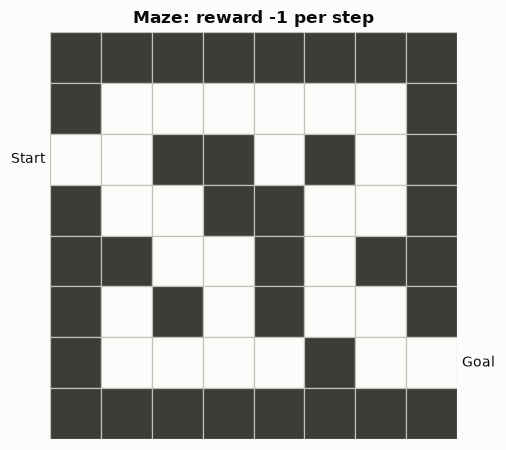

In [5]:
WALL_COLOR = "#3d3c38"


def text_color_on(face_rgba):
    """Black text on light cells, white text on dark cells."""
    r, g, b = face_rgba[:3]
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "#0b0b0b"


def draw_maze(ax, values=None, policy=None, path=None, unknown=None, title=None,
              vmin=-24, vmax=-1, fmt="{:.0f}"):
    """Draw the maze. values: dict cell->number, policy: dict cell->action,
    path: list of cells, unknown: set of open cells to grey out."""
    norm = Normalize(vmin, vmax)
    for r in range(H):
        for c in range(W):
            if WALL[r, c]:
                face = mpl.colors.to_rgba(WALL_COLOR)
            elif unknown is not None and (r, c) in unknown:
                face = mpl.colors.to_rgba("#e1e0d9")
            elif values is not None and np.isfinite(values.get((r, c), np.nan)):
                face = SEQ_CMAP(norm(values[(r, c)]))
            else:
                face = mpl.colors.to_rgba("#fcfcfb")
            ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=face, edgecolor="#c3c2b7", lw=0.8))
            if values is not None and (r, c) in values and not WALL[r, c]:
                v = values[(r, c)]
                label = fmt.format(v) if np.isfinite(v) else "?"
                ax.text(c, r, label, ha="center", va="center", fontsize=9, color=text_color_on(face), zorder=4,
                        bbox=dict(boxstyle="round,pad=0.12", fc=face, ec="none"))
    if policy is not None:
        for (r, c), a in policy.items():
            dr, dc = ACTIONS[a]
            ax.annotate("", xy=(c + 0.36 * dc, r + 0.36 * dr), xytext=(c - 0.36 * dc, r - 0.36 * dr),
                        arrowprops=dict(arrowstyle="-|>", color=PALETTE[1], lw=1.8, mutation_scale=11))
    if path is not None and len(path) > 1:
        ys, xs = zip(*path)
        ax.plot(xs, ys, color=PALETTE[1], lw=3, alpha=0.9, solid_capstyle="round", zorder=3)
    ax.text(START[1] - 0.6, START[0], "Start", ha="right", va="center", fontsize=9)
    ax.text(GOAL[1] + 0.6, GOAL[0], "Goal", ha="left", va="center", fontsize=9)
    ax.set_xlim(-0.5, W - 0.5)
    ax.set_ylim(H - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    if title:
        ax.set_title(title)


fig, ax = plt.subplots(figsize=(4.6, 4.2))
draw_maze(ax, title="Maze: reward -1 per step")
plt.tight_layout()
plt.show()

## 3. 정책으로 풀기 (Maze Example: RL-Solution by Policy)

정책(policy)이 명시적으로 주어진 경우입니다: 모든 칸마다 "어느 방향으로 갈지"가 정해져 있습니다.
슬라이드 그림의 화살표를 그대로 옮겨 적고, Start에서 이 정책을 따라가 봅니다.

following the slide policy from Start: 16 steps until exit, return G = -16


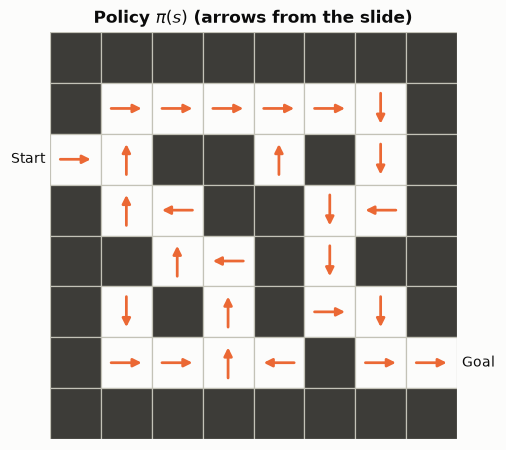

In [6]:
# 슬라이드 그림의 화살표 (row, col) -> action
SLIDE_POLICY = {
    (1, 1): "E", (1, 2): "E", (1, 3): "E", (1, 4): "E", (1, 5): "E", (1, 6): "S",
    (2, 0): "E", (2, 1): "N", (2, 4): "N", (2, 6): "S",
    (3, 1): "N", (3, 2): "W", (3, 5): "S", (3, 6): "W",
    (4, 2): "N", (4, 3): "W", (4, 5): "S",
    (5, 1): "S", (5, 3): "N", (5, 5): "E", (5, 6): "S",
    (6, 1): "E", (6, 2): "E", (6, 3): "N", (6, 4): "W", (6, 6): "E", (6, 7): "E",
}
assert set(SLIDE_POLICY) == set(OPEN_CELLS)


def rollout(policy, s=START, max_steps=100):
    """Follow a deterministic policy; return visited cells and the return G (gamma = 1)."""
    path, G = [s], 0
    for _ in range(max_steps):
        s, r = maze_step(s, policy[s])
        G += r
        if s is TERMINAL:
            return path, G
        path.append(s)
    return path, G


path, G = rollout(SLIDE_POLICY)
print(f"following the slide policy from Start: {len(path)} steps until exit, return G = {G}")

fig, ax = plt.subplots(figsize=(4.6, 4.2))
draw_maze(ax, policy=SLIDE_POLICY, title="Policy $\\pi(s)$ (arrows from the slide)")
plt.tight_layout()
plt.show()

정책만 있으면 각 칸에서 할 행동을 바로 읽어 낼 수 있습니다. Start에서 출발하면 16걸음 만에 빠져나가고 반환값은 $G=-16$입니다.

## 4. 가치 함수로 풀기 (Maze Example: RL-Solution by Value Function)

이번에는 각 칸의 가치 $v(s)$ (그 칸에서 출발했을 때의 반환값)를 구합니다. $\gamma=1$이고 결정적인 미로이므로

$$v(s) = \max_{a}\bigl[-1 + v(s')\bigr], \qquad v(\text{terminal}) = 0$$

을 모든 칸에서 반복해 갱신하면 됩니다(가치 반복, value iteration — 4주차에 자세히 다룹니다).
그다음 정책은 "이웃 중 가치가 가장 높은 쪽으로 이동"으로 **암묵적으로** 얻어집니다.

value iteration converged after 25 sweeps


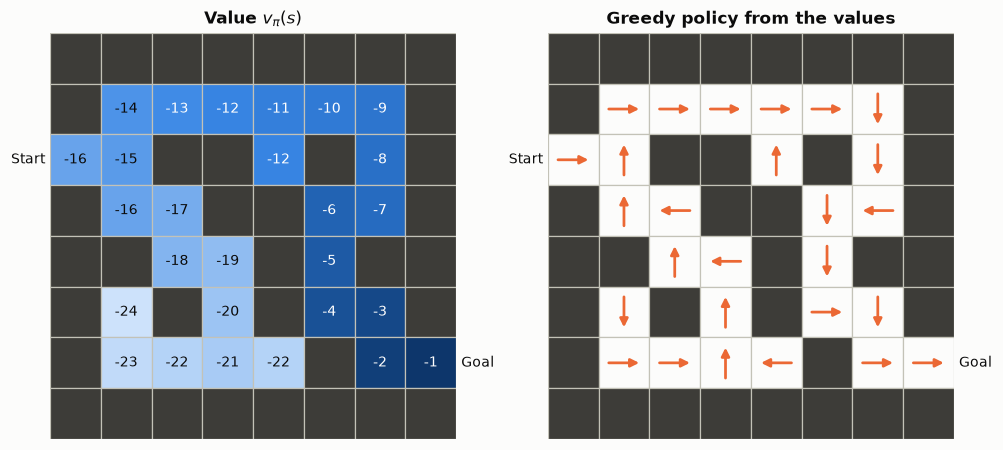

In [7]:
def maze_value_iteration():
    """v(s) = max_a [-1 + v(s')] with v(terminal) = 0, repeated until nothing changes."""
    V = {s: 0.0 for s in OPEN_CELLS}
    V[TERMINAL] = 0.0
    for sweep in range(1, 1000):
        V_new = {s: max(r + V[s2] for s2, r in (maze_step(s, a) for a in ACTIONS)) for s in OPEN_CELLS}
        V_new[TERMINAL] = 0.0
        if V_new == V:
            return V, sweep
        V = V_new


def greedy_policy(V):
    """pi(s) = argmax_a [r + v(s')]  (one-step look-ahead on the values)."""
    return {s: max(ACTIONS, key=lambda a: maze_step(s, a)[1] + V[maze_step(s, a)[0]]) for s in OPEN_CELLS}


V_maze, n_sweeps = maze_value_iteration()
print(f"value iteration converged after {n_sweeps} sweeps")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.2))
draw_maze(axes[0], values=V_maze, title="Value $v_\\pi(s)$")
draw_maze(axes[1], policy=greedy_policy(V_maze), title="Greedy policy from the values")
plt.tight_layout()
plt.show()

### 슬라이드와 비교

In [8]:
SLIDE_VALUES = {
    (1, 1): -14, (1, 2): -13, (1, 3): -12, (1, 4): -11, (1, 5): -10, (1, 6): -9,
    (2, 0): -16, (2, 1): -15, (2, 4): -12, (2, 6): -8,
    (3, 1): -16, (3, 2): -17, (3, 5): -6, (3, 6): -7,
    (4, 2): -18, (4, 3): -19, (4, 5): -5,
    (5, 1): -24, (5, 3): -20, (5, 5): -4, (5, 6): -3,
    (6, 1): -23, (6, 2): -22, (6, 3): -21, (6, 4): -22, (6, 6): -2, (6, 7): -1,
}
print("cell     slide  computed")
for s in [START, (1, 1), (1, 6), (2, 4), (5, 1), GOAL]:
    print(f"{str(s):8} {SLIDE_VALUES[s]:5d}  {V_maze[s]:8.0f}")
assert all(V_maze[s] == SLIDE_VALUES[s] for s in OPEN_CELLS)
assert greedy_policy(V_maze) == SLIDE_POLICY
print(f"all {len(OPEN_CELLS)} values and all {len(SLIDE_POLICY)} arrows match the slide")

cell     slide  computed
(2, 0)     -16       -16
(1, 1)     -14       -14
(1, 6)      -9        -9
(2, 4)     -12       -12
(5, 1)     -24       -24
(6, 7)      -1        -1
all 27 values and all 27 arrows match the slide


27칸의 가치와 화살표가 모두 슬라이드와 일치합니다. 가치는 "출구까지 남은 걸음 수"에 마이너스를 붙인 값이고,
가치가 가장 낮은 칸($-24$)은 Start에서 가깝지만 막다른 길 깊숙이 있는 왼쪽 아래 칸입니다. 정책은 가치 함수에서 한 단계 앞을 내다봐 얻어졌습니다.

## 5. 모델로 풀기 (Maze Example: RL-Solution by Model Evaluation)

모델 기반(model-based) 에이전트는 경험 $(s, a, r, s')$로부터 환경의 **모델** — 전이 $\hat{\mathcal{P}}^a_{ss'}$와 보상 $\hat{\mathcal{R}}^a_s$ — 을
만들고, 실제로 움직이기 전에 그 모델 안에서 계획(planning)합니다.

여기서는 에이전트가 무작위로 걸어 다니며(random walk) 경험을 모으고, 모은 스텝 수(예산)에 따라 모델이 얼마나 완전한지,
그 모델로 세운 계획이 무엇인지 봅니다. 모델에서 한 번도 시도하지 않은 칸은 모델이 모릅니다(불완전한 모델).

  150 steps: known cells 13, cells with a planned route  0, learned rewards R_hat = [-1.0]
  330 steps: known cells 17, cells with a planned route 17, learned rewards R_hat = [-1.0]
 1000 steps: known cells 27, cells with a planned route 27, learned rewards R_hat = [-1.0]


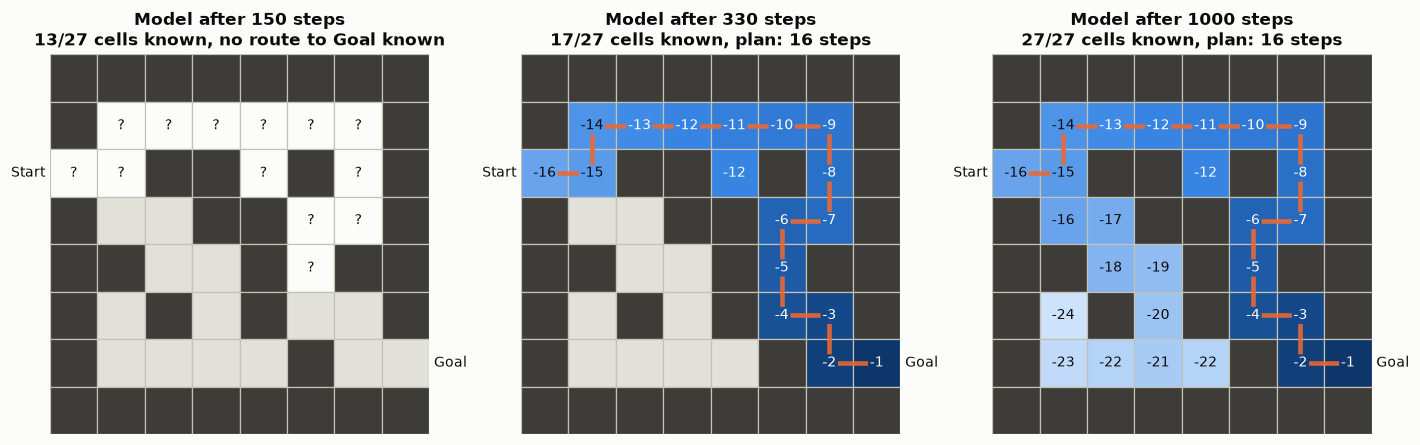

In [9]:
def explore(n_steps, rng):
    """Random-walk exploration for n_steps steps in total (restart at Start after exiting).
    Returns the list of experienced transitions (s, a, r, s_next)."""
    transitions, s = [], START
    for _ in range(n_steps):
        a = list(ACTIONS)[rng.integers(4)]
        s_next, r = maze_step(s, a)
        transitions.append((s, a, r, s_next))
        s = START if s_next is TERMINAL else s_next
    return transitions


def build_model(transitions):
    """Tabular model from counts: model[s][a] = (mean reward, {s_next: probability})."""
    counts, reward_sum = {}, {}
    for s, a, r, s_next in transitions:
        c = counts.setdefault(s, {}).setdefault(a, {})
        c[s_next] = c.get(s_next, 0) + 1
        reward_sum[(s, a)] = reward_sum.get((s, a), 0) + r
    model = {}
    for s in counts:
        model[s] = {}
        for a, c in counts[s].items():
            n = sum(c.values())
            model[s][a] = (reward_sum[(s, a)] / n, {s2: k / n for s2, k in c.items()})
    return model


def plan_with_model(model):
    """Value iteration inside the learned model (gamma = 1). Only tried actions are used.
    Values start at -inf, so a cell stays -inf until the model knows a route to the exit."""
    V = {s: -np.inf for s in model}
    V[TERMINAL] = 0.0
    for _ in range(1000):
        changed = False
        for s in model:
            best = max(r_hat + sum(p * V.get(s2, -np.inf) for s2, p in P_hat.items())
                       for r_hat, P_hat in model[s].values())
            if best != V[s]:
                V[s], changed = best, True
        if not changed:
            return V


def planned_path(model, V, s=START, max_steps=100):
    """Follow the greedy plan inside the model from s."""
    path = [s]
    for _ in range(max_steps):
        if s not in model or not np.isfinite(V[s]):
            return path
        a = max(model[s], key=lambda a: model[s][a][0] + sum(p * V.get(s2, -np.inf) for s2, p in model[s][a][1].items()))
        s = max(model[s][a][1], key=model[s][a][1].get)
        if s is TERMINAL:
            return path
        path.append(s)
    return path


budgets = [150, 330, 1000]
rng_model = np.random.default_rng(2)
experience = explore(budgets[-1], rng_model)          # 하나의 경험 흐름에서 앞부분만 잘라 씁니다

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, n in zip(axes, budgets):
    model = build_model(experience[:n])
    V_model = plan_with_model(model)
    known = set(model)
    unknown = set(OPEN_CELLS) - known
    shown = {s: V_model[s] for s in known}
    path = planned_path(model, V_model) if np.isfinite(V_model.get(START, -np.inf)) else None
    status = f"plan: {len(path)} steps" if path else "no route to Goal known"
    draw_maze(ax, values=shown, unknown=unknown, path=path,
              title=f"Model after {n} steps\n{len(known)}/{len(OPEN_CELLS)} cells known, {status}")
    # 슬라이드와 비교: 모델 안에서 경로를 아는 칸의 가치는 실제 가치와 같아야 함
    finite = [s for s in known if np.isfinite(V_model[s])]
    assert all(V_model[s] == V_maze[s] for s in finite)
    rewards_seen = {model[s][a][0] for s in model for a in model[s]}
    print(f"{n:5d} steps: known cells {len(known):2d}, cells with a planned route {len(finite):2d}, "
          f"learned rewards R_hat = {sorted(rewards_seen)}")
plt.tight_layout()
plt.show()

회색 칸은 아직 모델에 없는 칸, 숫자는 **모델 안에서** 계획한 가치, 주황 선은 Start에서 모델로 세운 계획입니다 ("?"는 방문은 했지만 모델이 아직 출구까지 가는 길을 모르는 칸).

- 경험이 적으면 모델이 불완전해서 출구로 가는 계획을 세울 수 없습니다.
- 출구를 한 번이라도 경험하면 모델 안에서의 계획만으로 최단 경로(16걸음)를 찾습니다. 경로를 아는 칸의 계획 가치는 4절의 실제 가치와 같습니다.
- 이 미로는 결정적이므로 관찰된 보상 $\hat{\mathcal{R}}$은 항상 정확히 $-1$입니다. 슬라이드 그림의 $-2, -4, -3$ 같은 값은 "모델은 추정치라서 틀릴 수 있다"를 보여 주기 위한 예시입니다.

## 직접 해보기

1. 1절에서 "4스텝 뒤 $+5$"를 "10스텝 뒤 $+5$"로 바꾸면 두 선택이 같아지는 $\gamma$는 어떻게 되나요? ($\gamma^{10}\cdot 5 = 1$)
2. `MAZE`에서 벽 하나(예: 칸 `(4, 6)`, 즉 `MAZE[4]`의 7번째 글자)를 `.`로 바꿔 지름길을 만들고 4절을 다시 실행해 보세요.
   가치와 화살표가 어떻게 바뀌나요? (슬라이드와 비교하는 `assert`는 당연히 실패합니다.)
3. `maze_step`에서 벽에 부딪혔을 때의 보상을 $-1$에서 $-5$로 바꾸면 최적 가치/정책이 바뀌나요? 왜 그런가요?
4. 5절에서 `rng_model`의 시드나 `budgets`를 바꿔 보세요. 출구를 처음 경험하는 데 보통 몇 스텝이 걸리나요?